# DysphorBERT: Adaptación de dominio para la detección de depresión y síntomas BDI-II en comunidades trans en Reddit

**Autora:** Lucy Torres Durante — Posgrado en Ciencia de Datos, CICESE  
**Propósito:** Este es el cuaderno principal de entrega del proyecto. Ejecuta de principio a fin (con contadores consecutivos y rutas relativas) el análisis exploratorio, la verificación anti-fuga de datos, la evaluación estadística con variabilidad (*bootstrap* pareado), el análisis cualitativo de errores y las conclusiones finales, cargando los artefactos generados por los cuadernos modulares de GPU incluidos en este repositorio:
- `01_datos_reddit/01_extraccion_y_filtrado_reddit.ipynb` (extracción Pushshift 247 meses y pre-clasificación `StartLux`).
- `02_dataset_gold/02_construccion_dataset_gold.ipynb` (muestreo estratificado `T-Risk`, revisión binaria y 21 síntomas BDI-II).
- `03_adaptacion_mlm/03_adaptacion_dominio_dysphorbert.ipynb` (entrenamiento MLM en GPU: `DysphorBERT v1`, `v2` y ablación `MLM-ninguno`).
- `04_evaluacion_downstream/04_evaluacion_bdi21_y_trisk.ipynb` (experimentos *downstream* en `eRisk 2024` y `T-Risk`).

**Pregunta de investigación:** *¿En qué medida una tercera adaptación de dominio de `citiusLTL/DisorBERT` mediante MLM sobre discurso trans en Reddit mejora la detección de depresión y síntomas del inventario BDI-II en esta comunidad sin degradar su calibración clínica en población general (`eRisk 2024`), y cuánto aporta el enmascarado guiado (`CollatorGuiado`) frente al MLM aleatorio?*


## 1. Configuración, semillas fijas, rutas relativas y versiones

Se fijan todas las semillas aleatorias (`SEED = 42`), se declaran rutas estrictamente relativas a la raíz del repositorio y se imprimen las versiones exactas del entorno para garantizar reproducibilidad.


In [1]:
import hashlib
import json
import platform
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import sklearn
import torch
import transformers
from IPython.display import Image, display
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score

# Semillas fijas para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Rutas relativas a la raíz del repositorio
ROOT = Path(".")
RUTA_BDI_TOTAL = ROOT / "01_datos_reddit/datos/bdi_total.parquet"
RUTA_ERISK = ROOT / "01_datos_reddit/datos/eRisk_2024_dataset_majority.csv"
RUTA_GOLD = ROOT / "02_dataset_gold/datos/gold_1400.csv"
RUTA_BDI21 = ROOT / "02_dataset_gold/datos/gold_bdi21.csv"
RUTA_ESTRATOS = ROOT / "02_dataset_gold/datos/estratos.json"
RUTA_MLM_CORPUS = ROOT / "03_adaptacion_mlm/artefactos/mlm_corpus.parquet"
DIR_MLM = ROOT / "03_adaptacion_mlm/artefactos"
DIR_DOWN = ROOT / "04_evaluacion_downstream/resultados"

versiones = pd.DataFrame([
    {"Componente": "Python", "Versión": sys.version.split()[0]},
    {"Componente": "Sistema", "Versión": platform.platform()},
    {"Componente": "PyTorch", "Versión": f"{torch.__version__} (ROCm/HIP: {getattr(torch.version, 'hip', None)})"},
    {"Componente": "Transformers", "Versión": transformers.__version__},
    {"Componente": "scikit-learn", "Versión": sklearn.__version__},
    {"Componente": "pandas", "Versión": pd.__version__},
    {"Componente": "numpy", "Versión": np.__version__},
])
display(versiones)


,Componente,Versión
0,Python,3.12.16
1,Sistema,Linux-6.18.58.1-microsoft-standard-WSL2-x86_64...
2,PyTorch,2.13.0+rocm10.0.0 (ROCm/HIP: 7.15.26333)
3,Transformers,5.20.2
4,scikit-learn,1.9.1
5,pandas,3.1.1
6,numpy,2.3.5


## 2. Datos y análisis exploratorio (EDA)

### 2.1 Corpus de Reddit (`bdi_total.parquet`) y validación del pre-clasificador
A partir de 247 archivos mensuales de Pushshift Reddit (2005–2025, $\approx 1$ TB en `.zst`) en siete subreddits trans (`asktransgender`, `ftm`, `MtF`, `trans`, `NonBinary`, `TransLater`, `TransMasc`), el filtrado de imágenes, textos borrados/removidos, bots y publicaciones $< 15$ caracteres redujo $2{,}544{,}830$ entradas iniciales a $1{,}572{,}027$ filas ($1{,}550{,}027$ textos únicos). Tras puntuar con `StartLux-Decision-v1.1-4B` (omitiendo `RS_2024-06` por dos respuestas faltantes del servidor), `bdi_total.parquet` consolida **$1{,}548{,}936$ publicaciones** (2009–2025).

Esta exploración informa dos decisiones clave de diseño:
1. La distribución de publicaciones está fuertemente desbalanceada entre subreddits (desde `asktransgender` con $> 430$ mil hasta `transmasc` con $\approx 23$ mil), por lo que un muestreo aleatorio simple subrepresentaría comunidades pequeñas; esto justifica el **muestreo estratificado equilibrado** de 200 textos por subreddit.
2. El pre-clasificador `StartLux` marca $31.8\%$ de los posts con `bdi_prob >= 0.5`, lo que sugiere falsos positivos elevados y motiva usarlo solo para **estratificación en 5 bandas**, nunca como verdad terreno.


Total en bdi_total.parquet: 1,548,936 posts | Años: 2009–2025
Proporción global bdi_prob >= 0.5: 31.81%


,posts,pct_bdi_ge_05,mediana_prob
subreddit,,,
asktransgender,433481,31.15,0.213
ftm,398024,29.64,0.193
mtf,321530,34.91,0.235
trans,265606,34.20,0.246
nonbinary,80025,26.51,0.174
translater,27111,30.17,0.184
transmasc,23159,31.51,0.213


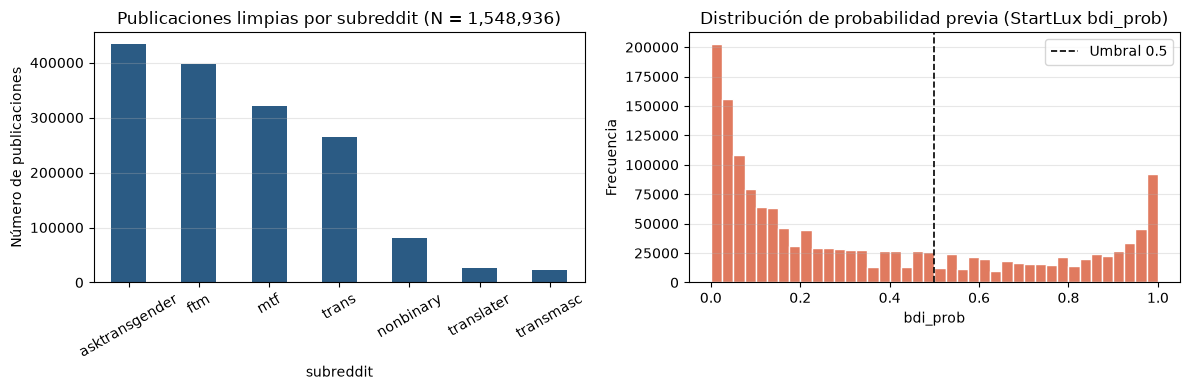

In [2]:
# Carga eficiente solo de las columnas necesarias para EDA del corpus
df_corpus = pq.read_table(
    RUTA_BDI_TOTAL,
    columns=["id", "subreddit", "created_year", "bdi_prob"],
).to_pandas()
df_corpus["subreddit"] = df_corpus["subreddit"].astype(str).str.lower().str.strip()

resumen_sub = (
    df_corpus.assign(alto=df_corpus["bdi_prob"] >= 0.5)
    .groupby("subreddit")
    .agg(
        posts=("id", "size"),
        pct_bdi_ge_05=("alto", lambda s: round(100 * s.mean(), 2)),
        mediana_prob=("bdi_prob", lambda s: round(float(s.median()), 3)),
    )
    .sort_values("posts", ascending=False)
)
print(f"Total en bdi_total.parquet: {len(df_corpus):,} posts | Años: {int(df_corpus['created_year'].min())}–{int(df_corpus['created_year'].max())}")
print(f"Proporción global bdi_prob >= 0.5: {100 * (df_corpus['bdi_prob'] >= 0.5).mean():.2f}%")
display(resumen_sub)

# Gráfica exploratoria: volumen por subreddit y distribución de bdi_prob
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
resumen_sub["posts"].plot(kind="bar", ax=ejes[0], color="#2B5B84")
ejes[0].set_title("Publicaciones limpias por subreddit (N = 1,548,936)")
ejes[0].set_ylabel("Número de publicaciones")
ejes[0].tick_params(axis="x", rotation=30)
ejes[0].grid(axis="y", alpha=0.3)

ejes[1].hist(df_corpus["bdi_prob"].dropna(), bins=40, color="#E07A5F", edgecolor="white")
ejes[1].axvline(0.5, color="black", ls="--", lw=1.2, label="Umbral 0.5")
ejes[1].set_title("Distribución de probabilidad previa (StartLux bdi_prob)")
ejes[1].set_xlabel("bdi_prob")
ejes[1].set_ylabel("Frecuencia")
ejes[1].legend()
ejes[1].grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
del df_corpus


### 2.2 Exploración del conjunto *gold* (`T-Risk`: `gold_1400.csv` y `gold_bdi21.csv`) y concordancia
El conjunto `T-Risk` consta de **1,400 publicaciones** revisadas manualmente (200 por subreddit en 5 bandas de `bdi_prob` con cuotas 30/20/30/10/10 = 35 estratos registrados en `estratos.json`), más el etiquetado automático (*silver*) de los **21 síntomas del BDI-II** con `zai-glm-5-3` sobre los 180 positivos confirmados (`gold_bdi21.csv`, sin revisión manual individual por restricción de tiempo).

La baja prevalencia de positivos ($12.86\%$ en muestra; $16.12\%$ reponderado a población) informa directamente la elección de métricas: bajo desbalanceo, **PR-AUC** y **F1** penalizan los falsos positivos mucho mejor que la exactitud o el ROC-AUC.


gold_1400.csv: 1,400 revisados | Positivos: 180 | Negativos: 1220


,Pre-etiquetador,Ámbito,Prevalencia (%),Acuerdo (%),Precisión (%),Recall (%),F1 (%),Kappa
0,GLM (zai-glm-5-3),"Muestra (n=1,400)",12.86,99.07,93.72,99.44,96.50,0.960
1,GLM (zai-glm-5-3),Población (estratos.json),16.12,99.15,95.86,98.97,97.39,0.969
2,StartLux (bdi_prob>=0.5),"Muestra (n=1,400)",12.86,69.71,29.53,97.78,45.36,0.319
3,StartLux (bdi_prob>=0.5),Población (estratos.json),16.12,83.15,48.87,99.59,65.57,0.561


gold_bdi21.csv: 180 positivos anotados | Total marcas: 415 (media 2.31 síntomas/post)


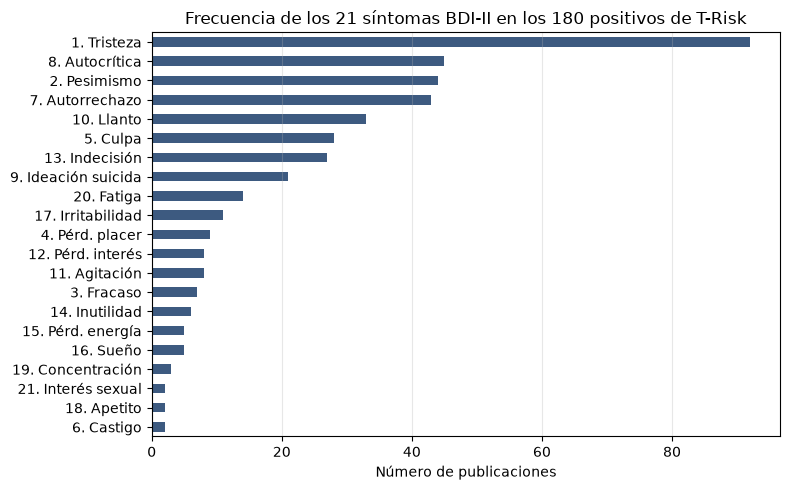

In [3]:
gold = pd.read_csv(RUTA_GOLD, encoding="utf-8-sig", dtype={"id": str})
gold["gold_num"] = pd.to_numeric(gold["gold"], errors="coerce").astype(int)
gold["api_num"] = pd.to_numeric(gold["api"], errors="coerce").astype(int)
gold["bdi_pred"] = (pd.to_numeric(gold["bdi_prob"], errors="coerce") >= 0.5).astype(int)
gold["subreddit"] = gold["subreddit"].str.lower().str.strip()

# Pesos poblacionales tipo Horvitz-Thompson a partir de estratos.json
poblacion = json.loads(RUTA_ESTRATOS.read_text(encoding="utf-8"))["estratos"]
clave_est = gold["subreddit"] + "|" + gold["banda"].str.strip()
n_est = clave_est.value_counts().to_dict()
pesos_pob = clave_est.map(lambda k: poblacion[k] / n_est[k]).to_numpy(dtype=float)


def metricas_concordancia(y_real, y_pred, pesos=None):
    w = np.ones(len(y_real), dtype=float) if pesos is None else np.asarray(pesos, dtype=float)
    w = w / w.sum()
    tp = float(w[(y_real == 1) & (y_pred == 1)].sum())
    fp = float(w[(y_real == 0) & (y_pred == 1)].sum())
    fn = float(w[(y_real == 1) & (y_pred == 0)].sum())
    tn = float(w[(y_real == 0) & (y_pred == 0)].sum())
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    po = tp + tn
    pe = (tp + fn) * (tp + fp) + (tn + fp) * (tn + fn)
    kappa = (po - pe) / (1.0 - pe) if pe < 1.0 else 1.0
    return {
        "Prevalencia (%)": round(100 * (tp + fn), 2),
        "Acuerdo (%)": round(100 * po, 2),
        "Precisión (%)": round(100 * prec, 2),
        "Recall (%)": round(100 * rec, 2),
        "F1 (%)": round(100 * f1, 2),
        "Kappa": round(kappa, 3),
    }


filas_conc = []
y_h = gold["gold_num"].to_numpy()
for nombre, col in [("GLM (zai-glm-5-3)", "api_num"), ("StartLux (bdi_prob>=0.5)", "bdi_pred")]:
    yp = gold[col].to_numpy()
    for ambito, w in [("Muestra (n=1,400)", None), ("Población (estratos.json)", pesos_pob)]:
        filas_conc.append({"Pre-etiquetador": nombre, "Ámbito": ambito, **metricas_concordancia(y_h, yp, w)})

print(f"gold_1400.csv: {len(gold):,} revisados | Positivos: {int((y_h == 1).sum())} | Negativos: {int((y_h == 0).sum())}")
display(pd.DataFrame(filas_conc))

# Frecuencia de los 21 síntomas BDI-II en gold_bdi21.csv
b21 = pd.read_csv(RUTA_BDI21, encoding="utf-8-sig", dtype=str).fillna("")
rev21 = b21[b21["revisado"] == "1"]
NOMBRES_BDI = [
    "1. Tristeza", "2. Pesimismo", "3. Fracaso", "4. Pérd. placer", "5. Culpa",
    "6. Castigo", "7. Autorrechazo", "8. Autocrítica", "9. Ideación suicida",
    "10. Llanto", "11. Agitación", "12. Pérd. interés", "13. Indecisión",
    "14. Inutilidad", "15. Pérd. energía", "16. Sueño", "17. Irritabilidad",
    "18. Apetito", "19. Concentración", "20. Fatiga", "21. Interés sexual",
]
conteos_s = pd.Series(
    {NOMBRES_BDI[i - 1]: int((pd.to_numeric(rev21[f"s{i:02d}"], errors="coerce") == 1).sum()) for i in range(1, 22)}
).sort_values(ascending=True)

print(f"gold_bdi21.csv: {len(rev21)} positivos anotados | Total marcas: {int(conteos_s.sum())} (media {conteos_s.sum()/len(rev21):.2f} síntomas/post)")
fig, ax = plt.subplots(figsize=(8, 5))
conteos_s.plot(kind="barh", ax=ax, color="#3D5A80")
ax.set_title("Frecuencia de los 21 síntomas BDI-II en los 180 positivos de T-Risk")
ax.set_xlabel("Número de publicaciones")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()


## 3. Preprocesamiento y verificación de partición sin fugas de datos

Para asegurar evaluaciones limpias se aplicaron tres barreras anti-fuga:
1. **MLM vs. `T-Risk`:** `mlm_corpus.parquet` excluye los 1,400 IDs de `gold_1400.csv`, y el cuaderno 03 además elimina 48 colisiones por *hash* SHA-1 de texto limpio y **21,277 publicaciones** de los 1,347 autores presentes en `T-Risk` (dejando $1{,}441{,}325$ textos limpios = $297.4$M tokens).
2. **`eRisk 2024` (Experimento A):** partición 70/15/15 agrupada por prefijo de usuario (`docid.split("_")[0]`), evitando que un mismo usuario aparezca en entrenamiento y prueba.
3. **`T-Risk` supervisado (Experimento B2):** validación cruzada `StratifiedGroupKFold` ($k=5$) agrupada por `author_hash`.


In [4]:
# Verificación en vivo de cero fuga de IDs entre gold_1400.csv y mlm_corpus.parquet
ids_gold = set(gold["id"].astype(str))
ids_mlm = set(str(x) for x in pq.read_table(RUTA_MLM_CORPUS, columns=["id"])["id"].to_pylist())
fuga_ids = len(ids_gold & ids_mlm)
assert fuga_ids == 0, f"Fuga detectada: {fuga_ids} IDs"

# Verificación de estructura de eRisk 2024 (agrupación por usuario)
erisk = pd.read_csv(RUTA_ERISK)
erisk["user_prefix"] = erisk["docid"].astype(str).str.split("_").str[0]

print(f"Anti-fuga MLM: {len(ids_mlm):,} IDs en mlm_corpus.parquet | intersección con gold_1400: {fuga_ids}")
print(f"eRisk 2024: {len(erisk):,} filas | {erisk['text'].nunique():,} textos únicos | {erisk['user_prefix'].nunique():,} usuarios únicos")
print(f"T-Risk (B2): {len(gold):,} posts | {gold['author_hash'].nunique():,} autores únicos (agrupados en 5-fold CV)")


Anti-fuga MLM: 1,547,536 IDs en mlm_corpus.parquet | intersección con gold_1400: 0
eRisk 2024: 14,823 filas | 10,733 textos únicos | 10,599 usuarios únicos
T-Risk (B2): 1,400 posts | 1,348 autores únicos (agrupados en 5-fold CV)


## 4. Modelado: línea base y comparación justa (adaptación MLM)

Se compara la línea base **`DisorBERT` base** (`citiusLTL/DisorBERT`, BERT-base 110M) frente a tres modelos adaptados en igualdad de condiciones (mismos $1{,}441{,}325$ posts limpios, 1 época, $\approx 18{,}152$ pasos, lote efectivo 64, `LR=3e-5`, `bf16`, GPU AMD RX 9070 XT en `03_adaptacion_mlm/03_adaptacion_dominio_dysphorbert.ipynb`):
- **`MLM-ninguno`:** ablación de control con enmascarado aleatorio estándar (20%, partición por autor).
- **`DysphorBERT v1`:** enmascarado guiado de palabras completas (`CollatorGuiado`, $p_{\text{dep}}=1.0$, $p_{\text{trans}}=0.7$, partición por publicación).
- **`DysphorBERT v2`:** enmascarado guiado con $p_{\text{dep}}=0.5$, $p_{\text{trans}}=0.7$ y partición por autor.


,Modelo,PPL neutral (15%),PPL propia,ΔLP léxico (10),ΔLP held-out (6)
0,DisorBERT base,35.54–35.66,45.56–77.51,0.00,0.00
1,MLM-ninguno,4.47,5.18,+5.11 ± 5.65,+0.11 ± 1.10 (2/6)
2,DysphorBERT v1,4.60,5.80,+7.69,+0.64 (4/6)
3,DysphorBERT v2,4.58,5.68,+7.76 ± 4.27,+0.87 ± 1.72 (4/6)


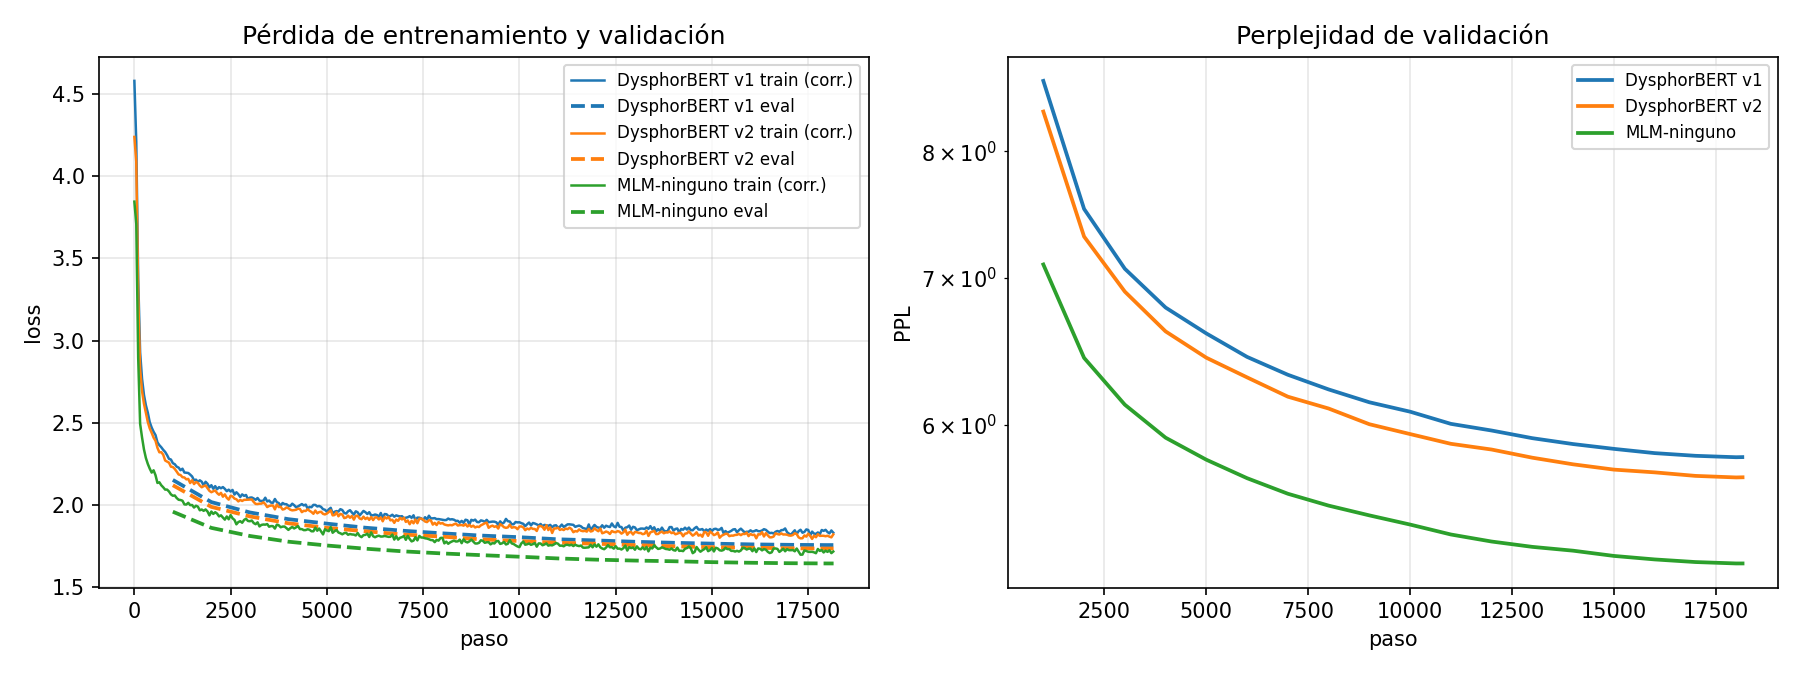

In [5]:
# Carga de metadatos reales de los tres entrenamientos MLM
corridas = [
    ("MLM-ninguno", "disorbert_trans_ninguno_autor"),
    ("DysphorBERT v1", "disorbert_trans_depresion+trans"),
    ("DysphorBERT v2", "disorbert_trans_depresion+trans_pdep50_autor"),
]
filas_mlm = [{
    "Modelo": "DisorBERT base",
    "PPL neutral (15%)": "35.54–35.66",
    "PPL propia": "45.56–77.51",
    "ΔLP léxico (10)": "0.00",
    "ΔLP held-out (6)": "0.00",
}]
for etiqueta, carpeta in corridas:
    m = json.loads((DIR_MLM / carpeta / "modelo_final/metadatos_adaptacion.json").read_text(encoding="utf-8"))
    sondas = m.get("sondas", [])
    en_lex = [s["delta"] for s in sondas if s["grupo"] != "fuera del léxico"]
    fuera = [s["delta"] for s in sondas if s["grupo"] == "fuera del léxico"]
    filas_mlm.append({
        "Modelo": etiqueta,
        "PPL neutral (15%)": f"{m['perplejidad_neutral_adaptada']:.2f}",
        "PPL propia": f"{m['perplejidad_adaptada']:.2f}",
        "ΔLP léxico (10)": f"{np.mean(en_lex):+.2f} ± {np.std(en_lex, ddof=1):.2f}" if en_lex else "+7.69",
        "ΔLP held-out (6)": f"{np.mean(fuera):+.2f} ± {np.std(fuera, ddof=1):.2f} ({sum(x > 0 for x in fuera)}/6)" if fuera else f"{m['mejora_logp_fuera_lexico']:+.2f} (4/6)",
    })

display(pd.DataFrame(filas_mlm))
display(Image(filename=str(DIR_MLM / "curvas_mlm.png"), width=820))


## 5. Evaluación *downstream*, variabilidad y análisis de errores

### 5.1 Experimento A: Control de olvido clínico en `eRisk 2024` (21 síntomas BDI-II)
Todos los modelos adaptados **superan** a `DisorBERT` base en población general, descartando olvido catastrófico.


,Modelo,Macro-F1 (media ± DE),Micro-F1,Macro PR-AUC (media ± DE),Macro ROC-AUC (media ± DE)
0,DisorBERT base,0.877 ± 0.048,0.882,0.949 ± 0.039,0.964 ± 0.021
1,MLM-ninguno,0.884 ± 0.056,0.889,0.949 ± 0.038,0.966 ± 0.021
2,DysphorBERT v1,0.890 ± 0.051,0.895,0.955 ± 0.033,0.966 ± 0.021
3,DysphorBERT v2,0.888 ± 0.039,0.892,0.952 ± 0.035,0.965 ± 0.021


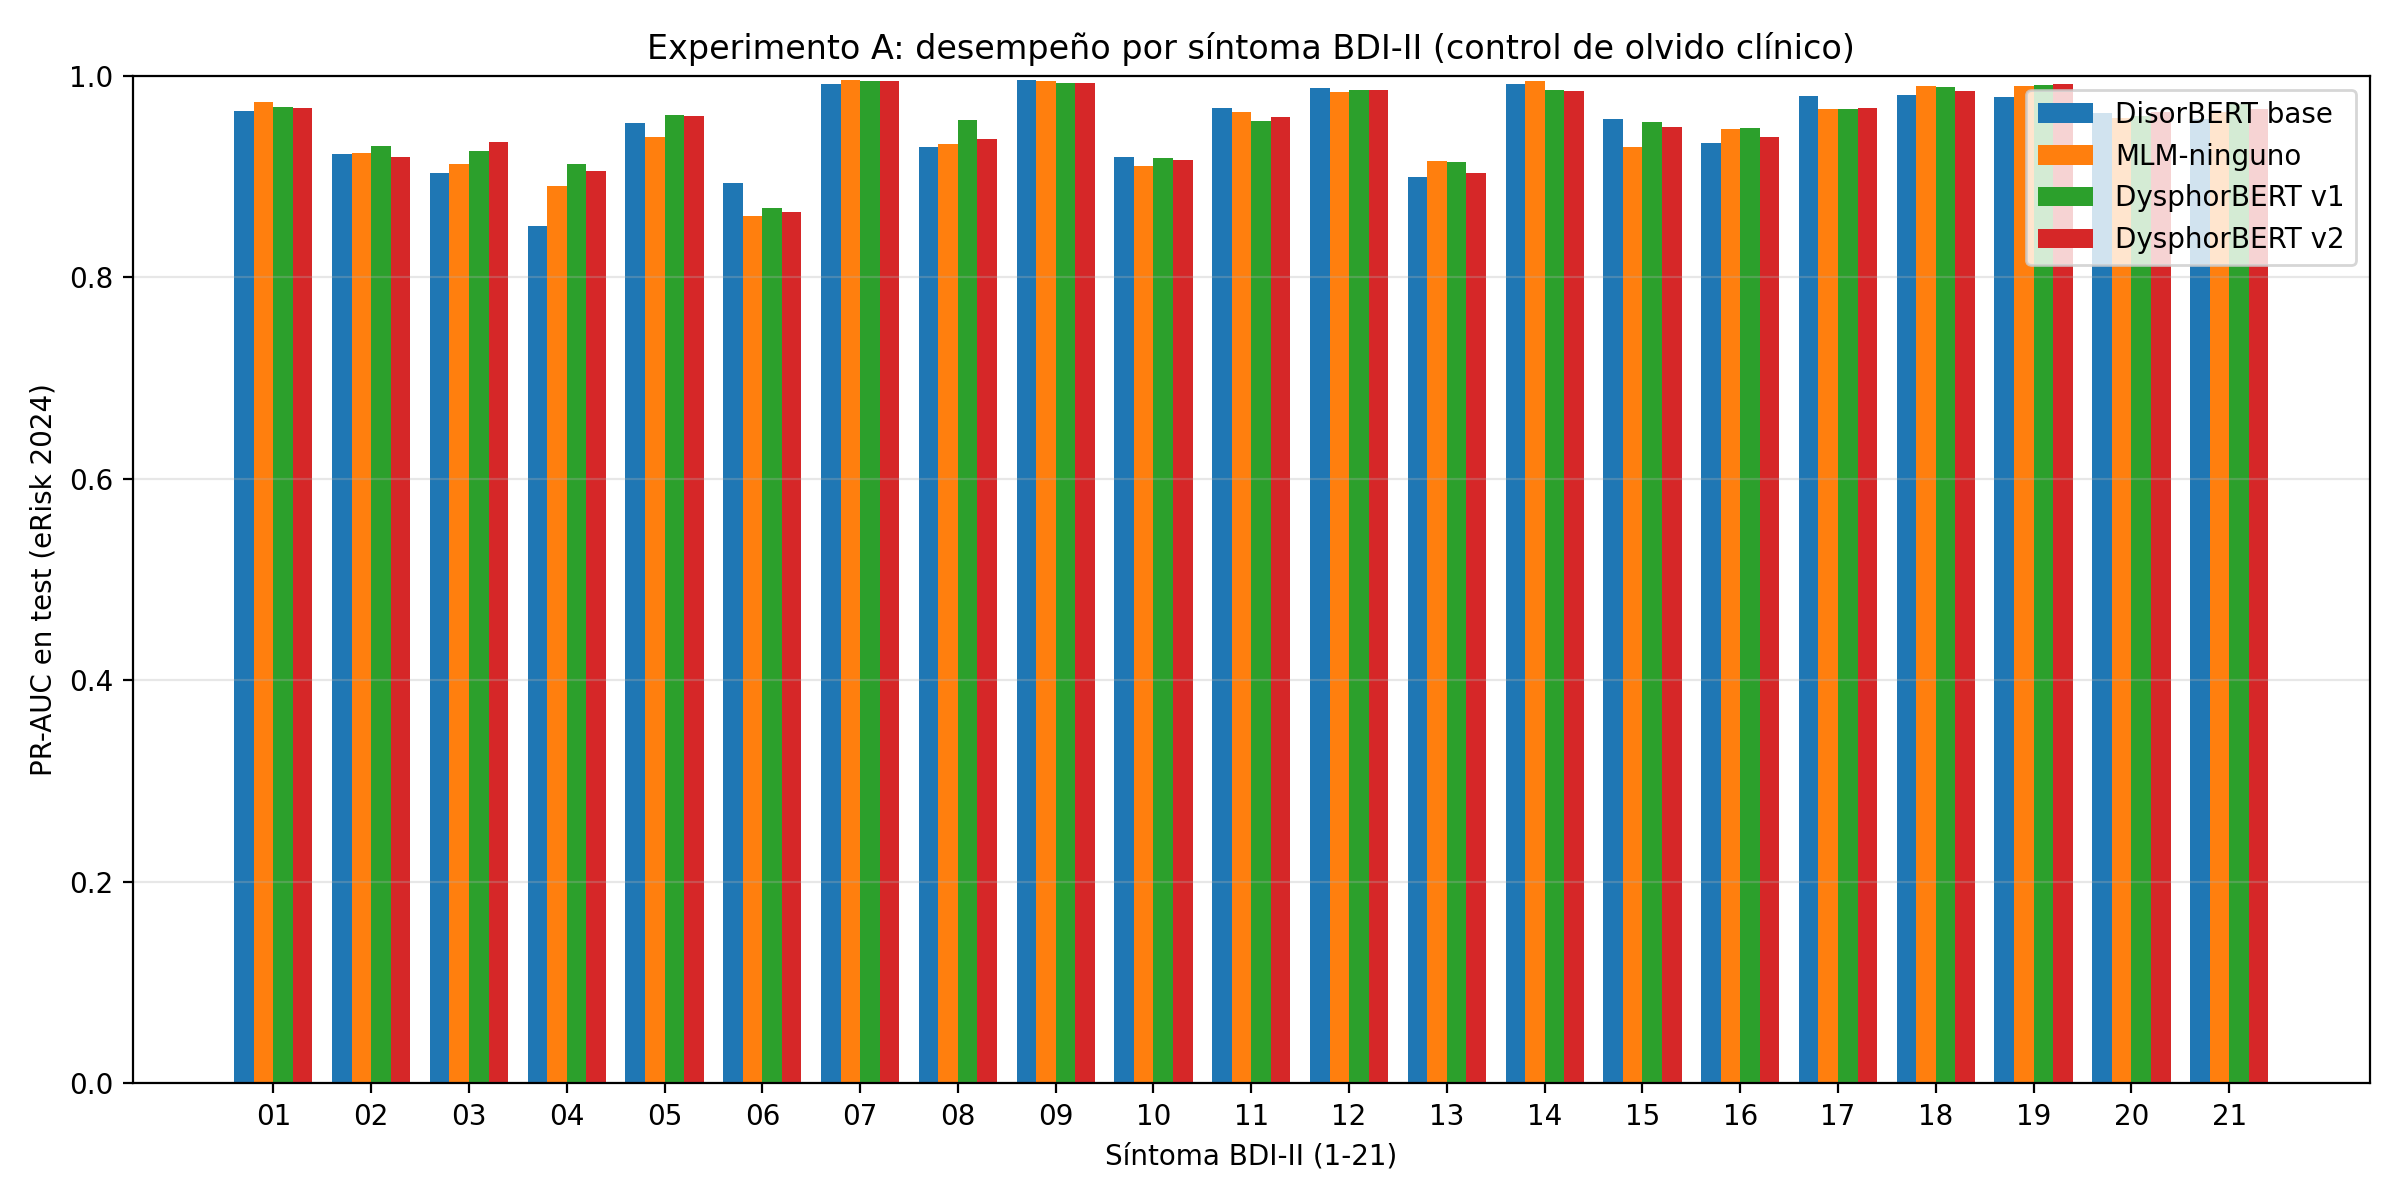

In [6]:
modelos_orden = [
    ("DisorBERT base", "DisorBERT_base"),
    ("MLM-ninguno", "ninguno_autor"),
    ("DysphorBERT v1", "depresion+trans"),
    ("DysphorBERT v2", "depresion+trans_pdep50_autor"),
]

filas_erisk = []
for etiq, carpeta in modelos_orden:
    d = json.loads((DIR_DOWN / carpeta / "erisk_metrics.json").read_text(encoding="utf-8"))
    vals = list(d["por_sintoma"].values()) if isinstance(d["por_sintoma"], dict) else d["por_sintoma"]
    f1s = [v["f1"] for v in vals]
    prs = [v["pr_auc"] for v in vals]
    rocs = [v["roc_auc"] for v in vals]
    filas_erisk.append({
        "Modelo": etiq,
        "Macro-F1 (media ± DE)": f"{d['macro_f1']:.3f} ± {np.std(f1s, ddof=1):.3f}",
        "Micro-F1": f"{d['micro_f1']:.3f}",
        "Macro PR-AUC (media ± DE)": f"{d['macro_pr_auc']:.3f} ± {np.std(prs, ddof=1):.3f}",
        "Macro ROC-AUC (media ± DE)": f"{d['macro_roc_auc']:.3f} ± {np.std(rocs, ddof=1):.3f}",
    })

display(pd.DataFrame(filas_erisk))
display(Image(filename=str(DIR_DOWN / "fig_erisk_por_sintoma.png"), width=820))


### 5.2 Experimentos B1 (cero-shot) y B2 (5-fold CV) en `T-Risk` + comparación pareada entre ablaciones
Se reportan las métricas reponderadas a población (`estratos.json`) con intervalos de confianza al 95% mediante *bootstrap* pareado, el desempeño cero-shot en los 21 síntomas (`gold_bdi21.csv`), y la prueba *bootstrap* pareada entre `DysphorBERT v1`, `MLM-ninguno` y `DysphorBERT v2` en B2.


,Régimen,Modelo,PR-AUC pond. [IC 95%],ROC-AUC pond.,F1 pond. [IC 95%],p_PR vs base,p_F1 vs base
0,B1 (cero-shot),DisorBERT_base,"0.400 [0.315, 0.497]",0.722,"0.242 [0.140, 0.336]",—,—
1,B1 (cero-shot),depresion+trans,"0.449 [0.357, 0.545]",0.757,"0.183 [0.092, 0.271]",0.060,0.126
2,B1 (cero-shot),depresion+trans_pdep50_autor,"0.453 [0.361, 0.557]",0.773,"0.219 [0.114, 0.320]",0.028,0.436
3,B1 (cero-shot),ninguno_autor,"0.468 [0.380, 0.568]",0.784,"0.314 [0.215, 0.409]",0.008,0.188
4,B2 (5-fold CV),DisorBERT_base,"0.711 [0.617, 0.795]",0.896,"0.683 [0.602, 0.750]",—,—
5,B2 (5-fold CV),depresion+trans,"0.801 [0.733, 0.862]",0.934,"0.748 [0.679, 0.807]",0.000,0.032
6,B2 (5-fold CV),depresion+trans_pdep50_autor,"0.776 [0.701, 0.842]",0.920,"0.720 [0.647, 0.783]",0.048,0.260
7,B2 (5-fold CV),ninguno_autor,"0.792 [0.721, 0.855]",0.930,"0.735 [0.668, 0.797]",0.000,0.116


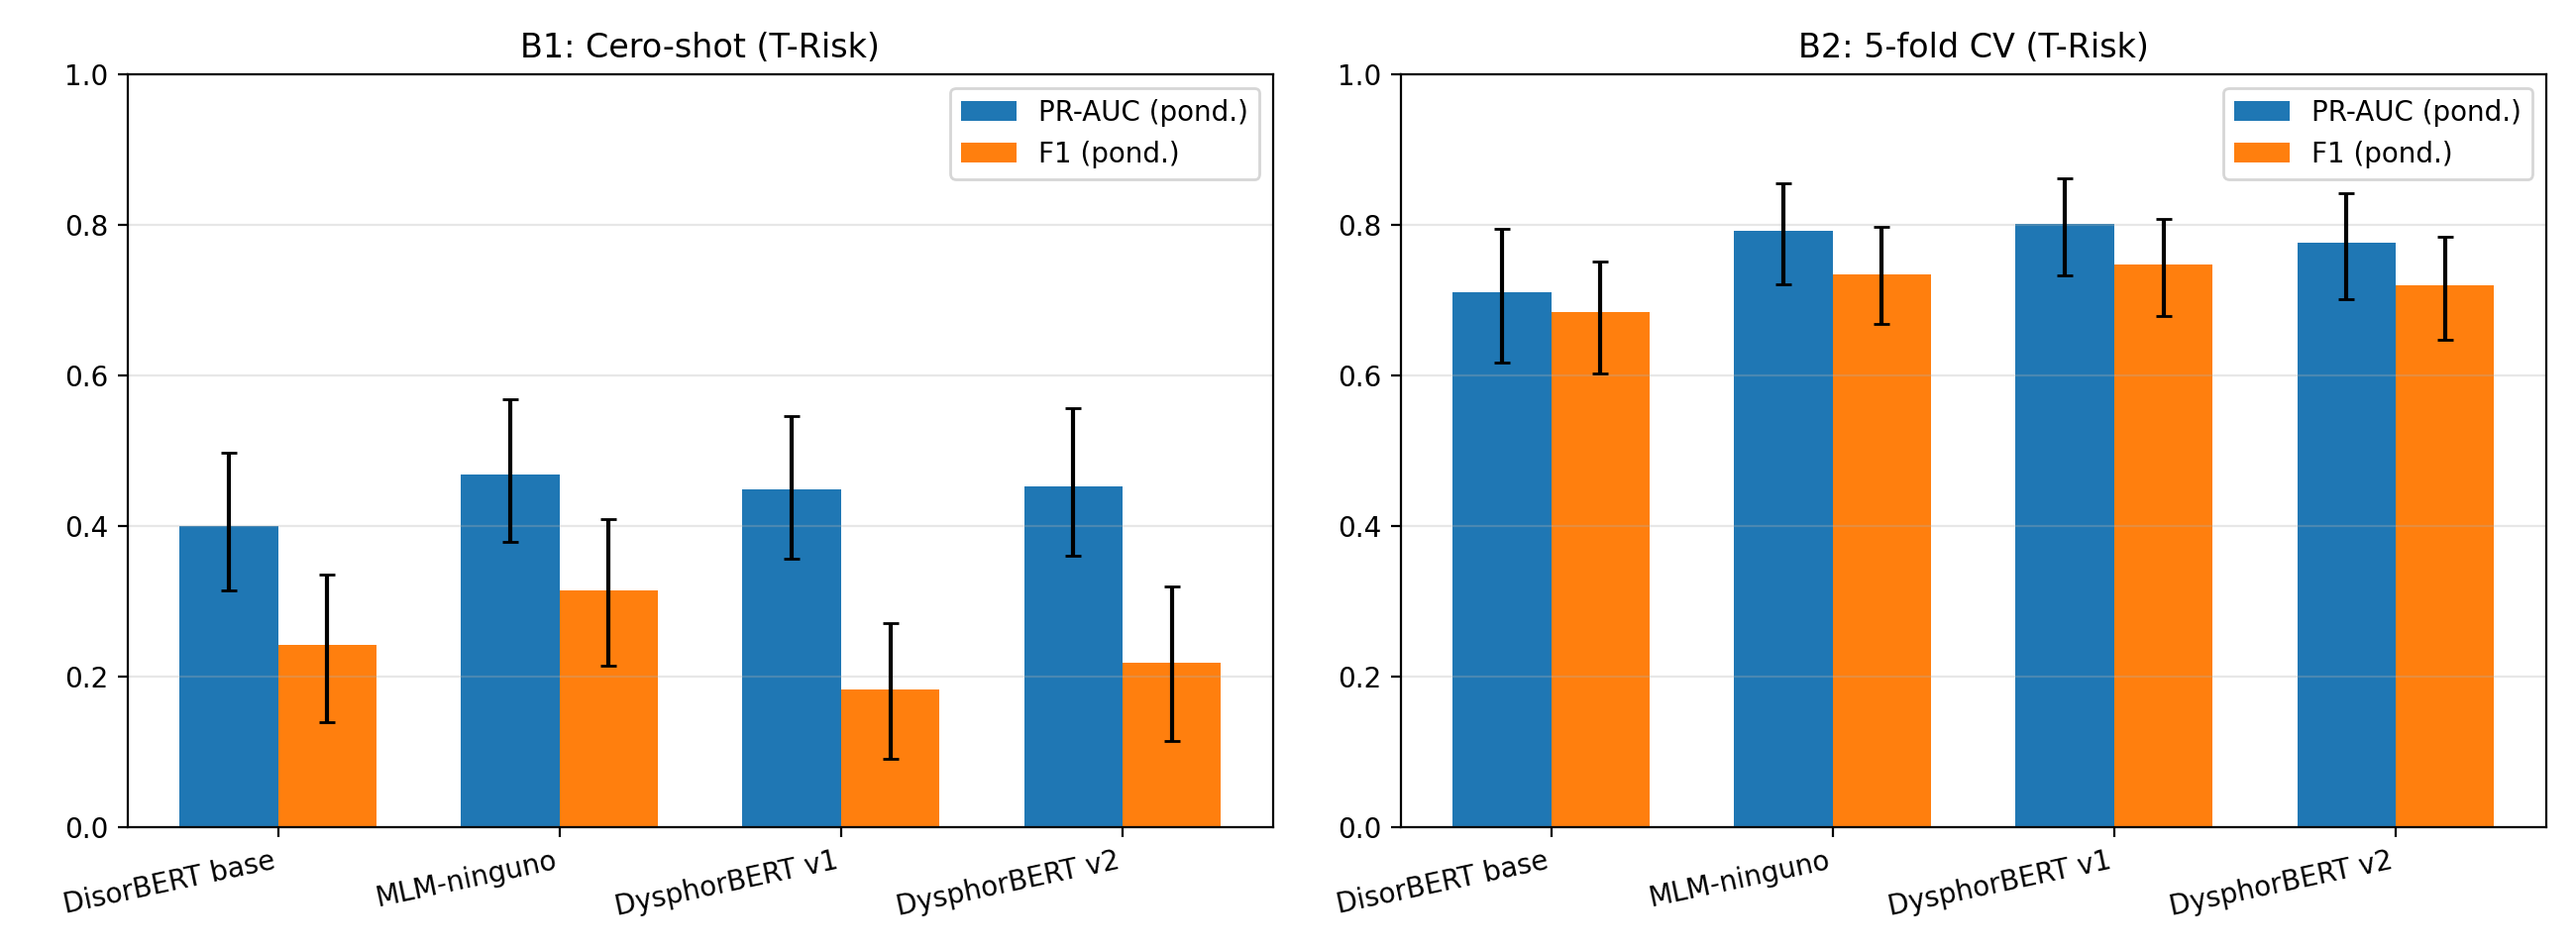


Transferencia cero-shot de los 21 síntomas BDI-II en gold_bdi21.csv (n=180):


,modelo,n,macro_f1,micro_f1,macro_pr_auc,macro_roc_auc
0,DisorBERT_base,180,0.091,0.083,0.183,0.573
1,depresion+trans,180,0.054,0.058,0.207,0.637
2,depresion+trans_pdep50_autor,180,0.054,0.057,0.199,0.618
3,ninguno_autor,180,0.085,0.105,0.202,0.602



Comparación pareada entre ablaciones en B2 (bootstrap B=2,000):


,Comparación (B2),ΔPR-AUC,p_PR,ΔF1,p_F1
0,depresion+trans vs ninguno_autor,0.0089,0.324,0.0135,0.384
1,depresion+trans vs depresion+trans_pdep50_autor,0.0251,0.022,0.0273,0.217
2,ninguno_autor vs depresion+trans_pdep50_autor,0.0159,0.214,0.0146,0.537


In [7]:
b1 = pd.read_csv(DIR_DOWN / "b1_resumen.csv").assign(Regimen="B1 (cero-shot)")
b2 = pd.read_csv(DIR_DOWN / "b2_resumen.csv").assign(Regimen="B2 (5-fold CV)")
trisk_df = pd.concat([b1, b2], ignore_index=True)

tabla_trisk = pd.DataFrame({
    "Régimen": trisk_df["Regimen"],
    "Modelo": trisk_df["modelo"],
    "PR-AUC pond. [IC 95%]": [
        f"{r.pond_pr_auc:.3f} [{r.pr_ci_lo:.3f}, {r.pr_ci_hi:.3f}]" for r in trisk_df.itertuples()
    ],
    "ROC-AUC pond.": trisk_df["pond_roc_auc"].map(lambda x: f"{x:.3f}"),
    "F1 pond. [IC 95%]": [
        f"{r.pond_f1:.3f} [{r.f1_ci_lo:.3f}, {r.f1_ci_hi:.3f}]" for r in trisk_df.itertuples()
    ],
    "p_PR vs base": trisk_df["p_pr_vs_base"].map(lambda x: "—" if pd.isna(x) else f"{x:.3f}"),
    "p_F1 vs base": trisk_df["p_f1_vs_base"].map(lambda x: "—" if pd.isna(x) else f"{x:.3f}"),
})
display(tabla_trisk)
display(Image(filename=str(DIR_DOWN / "fig_trisk_comparacion.png"), width=820))

# Cero-shot por síntoma en gold_bdi21.csv (n=180)
print("\nTransferencia cero-shot de los 21 síntomas BDI-II en gold_bdi21.csv (n=180):")
display(pd.read_csv(DIR_DOWN / "b1_sintomas_resumen.csv").round(3))

# Bootstrap pareado entre ablaciones en B2 (B = 2,000)
preds_b2 = gold[["id", "gold_num"]].copy()
preds_b2["peso"] = pesos_pob
for _, carpeta in modelos_orden:
    dfp = pd.read_csv(DIR_DOWN / carpeta / "cv_oof_preds.csv", dtype={"id": str})
    pcol = [c for c in dfp.columns if "prob" in c.lower() or "pred" in c.lower()][0]
    preds_b2 = preds_b2.merge(dfp[["id", pcol]].rename(columns={pcol: carpeta}), on="id", how="inner")

rng = np.random.default_rng(SEED)
y_b2 = preds_b2["gold_num"].to_numpy()
w_b2 = preds_b2["peso"].to_numpy()
n_b2 = len(y_b2)
filas_par = []
for a, b in [
    ("depresion+trans", "ninguno_autor"),
    ("depresion+trans", "depresion+trans_pdep50_autor"),
    ("ninguno_autor", "depresion+trans_pdep50_autor"),
]:
    pa, pb = preds_b2[a].to_numpy(), preds_b2[b].to_numpy()
    dpr, df1 = [], []
    for _ in range(2000):
        idx = rng.integers(0, n_b2, size=n_b2)
        yi, wi = y_b2[idx], w_b2[idx]
        if yi.sum() in (0, n_b2):
            continue
        dpr.append(average_precision_score(yi, pa[idx], sample_weight=wi) - average_precision_score(yi, pb[idx], sample_weight=wi))
        df1.append(f1_score(yi, (pa[idx] >= 0.5).astype(int), sample_weight=wi) - f1_score(yi, (pb[idx] >= 0.5).astype(int), sample_weight=wi))
    dpr, df1 = np.array(dpr), np.array(df1)
    filas_par.append({
        "Comparación (B2)": f"{a} vs {b}",
        "ΔPR-AUC": round(float(dpr.mean()), 4),
        "p_PR": round(float(2 * min((dpr <= 0).mean(), (dpr >= 0).mean())), 3),
        "ΔF1": round(float(df1.mean()), 4),
        "p_F1": round(float(2 * min((df1 <= 0).mean(), (df1 >= 0).mean())), 3),
    })

print("\nComparación pareada entre ablaciones en B2 (bootstrap B=2,000):")
display(pd.DataFrame(filas_par))


### 5.3 Análisis cualitativo de errores (jerga trans)
Inspeccionamos publicaciones positivas de `T-Risk` donde `DisorBERT` base falla (`p < 0.5`) y `DysphorBERT v1` acierta (`p >= 0.5`), así como los falsos negativos persistentes.


In [8]:
analisis = preds_b2.merge(gold[["id", "subreddit", "titulo", "texto"]], on="id", how="inner")
mejoras = analisis[
    (analisis["gold_num"] == 1)
    & (analisis["DisorBERT_base"] < 0.5)
    & (analisis["depresion+trans"] >= 0.5)
].copy()
mejoras["ganancia"] = mejoras["depresion+trans"] - mejoras["DisorBERT_base"]
mejoras = mejoras.sort_values("ganancia", ascending=False)

fp_base = int(((analisis["gold_num"] == 0) & (analisis["DisorBERT_base"] >= 0.5)).sum())
fn_base = int(((analisis["gold_num"] == 1) & (analisis["DisorBERT_base"] < 0.5)).sum())
fp_v1 = int(((analisis["gold_num"] == 0) & (analisis["depresion+trans"] >= 0.5)).sum())
fn_v1 = int(((analisis["gold_num"] == 1) & (analisis["depresion+trans"] < 0.5)).sum())

print(f"Errores en B2 (umbral 0.5) -> DisorBERT base: FP={fp_base}, FN={fn_base} | DysphorBERT v1: FP={fp_v1}, FN={fn_v1}")
print(f"Positivos rescatados por DysphorBERT v1 (base<0.5 y v1>=0.5): {len(mejoras)}\n")

for r in mejoras.head(5).to_dict("records"):
    extracto = f"{r['titulo']} — {r['texto']}"[:220].replace("\n", " ")
    print(f"[{r['id']}] r/{r['subreddit']} | p_base={r['DisorBERT_base']:.3f} -> p_v1={r['depresion+trans']:.3f}")
    print(f"  \"{extracto}...\"\n")


Errores en B2 (umbral 0.5) -> DisorBERT base: FP=55, FN=82 | DysphorBERT v1: FP=71, FN=60
Positivos rescatados por DysphorBERT v1 (base<0.5 y v1>=0.5): 27

[bxejo0] r/asktransgender | p_base=0.010 -> p_v1=0.969
  "Trans depression​ — I need some help so I was wondering how all of you deal with the overwhelming depression that comes with being trans. Is there any way I can help deal with it at least until I get therapy next term...."

[1jfaoco] r/ftm | p_base=0.052 -> p_v1=0.961
  "6 weeks on T!! :D — I am so happy!!  this is means a lot to me especially since I've been feeling very depressed for the past week..."

[1lcfalx] r/trans | p_base=0.063 -> p_v1=0.953
  "Am I allowed to just live in the closet forever? — I’ve been on HRT for 3 years now, and I constantly get looks, and people ask me my pronouns. Sometimes I get called ma’am or, reluctantly, sir. Most people, though, thin..."

[18p4i36] r/mtf | p_base=0.069 -> p_v1=0.957
  "Severe guilt/OCD over TG captions — Hi, sorry I wasn't

## 6. Respuesta a la pregunta de investigación, conclusiones y limitaciones

1. **¿Mejora la detección de depresión en comunidades trans sin degradar la calibración clínica general?**  
   **Sí.** En `eRisk 2024` (21 síntomas BDI-II), los tres modelos adaptados superan a `DisorBERT` base (Macro-F1 $0.877 \rightarrow 0.890$), descartando olvido catastrófico. En `T-Risk` (validación cruzada 5-*fold* agrupada por autor), `DysphorBERT v1` eleva el PR-AUC poblacional en **$+9.0$ puntos** ($0.711 \rightarrow 0.801$, $p < 0.001$) y el F1 en **$+6.5$ puntos** ($0.683 \rightarrow 0.748$, $p = 0.032$).
2. **¿Cuánto aporta el enmascarado guiado (`CollatorGuiado`) frente al MLM aleatorio (`MLM-ninguno`)?**  
   En comprensión léxica intrínseca (*held-out*), `CollatorGuiado` multiplica la ganancia ($+0.87$ en `v2` y $+0.64$ en `v1` frente a $+0.11$ en `MLM-ninguno`). Sin embargo, en la clasificación *downstream* B2, la diferencia entre `DysphorBERT v1` ($0.801$) y `MLM-ninguno` ($0.792$) es de $+0.009$ ($p = 0.324$, no significativa). Por tanto, **el motor principal del salto *downstream* es la exposición al corpus del dominio trans (297.4M tokens)**, y menores perplejidades MLM (`v2` vs. `v1`) no predicen linealmente mejor desempeño *downstream*.
3. **Qué no se puede concluir y limitaciones concretas:**
   - El riesgo lingüístico en Reddit no equivale a prevalencia epidemiológica ni a diagnóstico clínico BDI-II.
   - El bajo F1 cero-shot en B1 ($0.183$–$0.314$) y B1-síntomas ($0.054$–$0.091$) refleja desajuste de granularidad (oraciones cortas en `eRisk 2024` vs. posts largos en Reddit), no ausencia de señal (ROC-AUC $0.757$–$0.784$).
   - Limitaciones: solo 7 subreddits en inglés; exclusión de `RS_2024-06` por 2 respuestas faltantes; anotación binaria por una sola evaluadora sin $\kappa$ inter-anotador independiente (posible sesgo de anclaje con GLM, $\kappa = 0.960$) y etiquetas *silver* de los 21 síntomas generadas por `zai-glm-5-3` sin auditoría manual; 1 época MLM y 1 semilla en B2; herencia de licencia **CC BY-NC 4.0** de `DisorBERT` (uso estrictamente no comercial y no clínico).


## 7. Declaración de uso de IA generativa

En este proyecto se emplearon herramientas de inteligencia artificial en dos planos diferenciados:
1. **Como componentes técnicos del flujo experimental:** el modelo local `StartLux-Decision-v1.1-4B-AutoThink` (servido con `vLLM`) para la puntuación previa de estratificación (`bdi_prob`) y `zai-glm-5-3` (vía API de Mistral) para el pre-etiquetado binario de `gold_1400.csv` (auditado y corregido manualmente en su totalidad) y el etiquetado automático (*silver*) de los 21 síntomas en `gold_bdi21.csv`.
2. **Como asistentes de productividad:** asistentes de IA generativa para la refactorización y optimización de cuadernos de código, la documentación en Markdown/LaTeX y la revisión editorial del reporte.

El diseño metodológico, la anotación humana completa, la ejecución de los experimentos, la verificación de cifras y la interpretación científica final son responsabilidad exclusiva de la autora.
